# Imports

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.integrate import solve_ivp
from scipy.optimize import brentq

sigma = 5.670e-8                     # Stefan-Boltzmannova konstanta [W/(m^2 K^4)]
S0 = 1361.0                          # solarna konstanta [W/m^2]
leto = 3.156e7                       # [s]
C = 1000 * 4186 * 50                 # toplotna kapaciteta 50 m oceana na m^2 [J/(m^2 K)]

# Model 0D
Q0 = S0 / 4                          # povprečna vpadna gostota toka [W/m^2]

# Model 1D (North, Cahalan, Coakley 1981)
Q1, A, B, D = 334.4, 203.3, 2.09, 0.649
a0, a2, b0, s2, T_led = 0.681, -0.202, 0.38, -0.482, -10.0
N = 60
dx = 1.0 / N
x = (np.arange(N) + 0.5) * dx        # središča celic, x = sin(phi)
xr = np.arange(N + 1) * dx           # robovi celic
P2 = (3 * x**2 - 1) / 2

# Funkcije

In [2]:
# --- Model 0D ---
def T_ravn(alfa, eps, mu=1.0):
    """Ravnovesna temperatura [K] pri stalnem albedu: mu Q0 (1 - alfa) = eps sigma T^4."""
    return (mu * Q0 * (1 - alfa) / (eps * sigma))**0.25


def alfa_led(T, a_led=0.62, a_voda=0.30, T1=250.0, T2=280.0):
    """Albedo z ledeno povratno zanko: a_led pod T1, a_voda nad T2, vmes linearno."""
    return np.clip(a_led + (a_voda - a_led) * (T - T1) / (T2 - T1), min(a_led, a_voda), max(a_led, a_voda))


def neto_0d(T, mu=1.0, eps=0.61, alfa=alfa_led):
    """Neto gostota toka [W/m^2]: absorbirano sončno minus izsevano. alfa je funkcija T."""
    return mu * Q0 * (1 - alfa(T)) - eps * sigma * T**4


def potek_0d(T0, t_kon, **kw):
    """Časovni potek C dT/dt = neto_0d(T) s solve_ivp. Vrne (t [leta], T [K])."""
    t_eval = np.linspace(0, t_kon, 400)
    r = solve_ivp(lambda t, T: neto_0d(T, **kw) / C, (0, t_kon), [T0], t_eval=t_eval, rtol=1e-8)
    return r.t / leto, r.y[0]


def ravnovesja_0d(mu=1.0, eps=0.61, Tmin=150.0, Tmax=350.0):
    """Vse ničle neto_0d na [Tmin, Tmax] in njihova stabilnost (stabilno, če d(neto)/dT < 0)."""
    T = np.linspace(Tmin, Tmax, 2001)
    f = neto_0d(T, mu, eps)
    out = []
    for i in np.nonzero(f[:-1] * f[1:] < 0)[0]:
        Tr = brentq(neto_0d, T[i], T[i + 1], args=(mu, eps))
        odvod = (neto_0d(Tr + 0.01, mu, eps) - neto_0d(Tr - 0.01, mu, eps)) / 0.02
        out.append((Tr, odvod < 0))
    return out


# --- Model 1D ---
def koalbedo(T):
    """Delež absorbirane svetlobe: a0 + a2 P2(x) brez ledu, b0 na ledu (T < T_led)."""
    return np.where(T < T_led, b0, a0 + a2 * P2)


def korak_1d(T, mu, dt, D=D, A=A):
    """En korak FTCS za C dT/dt = mu Q1 s(x) a(x,T) - (A + B T) + D d/dx[(1 - x^2) dT/dx].
    Na robovih (ekvator x = 0, pol x = 1) je tok nič."""
    s = 1 + s2 * P2
    tok = np.zeros(N + 1)
    tok[1:-1] = (1 - xr[1:-1]**2) * (T[1:] - T[:-1]) / dx
    div = (tok[1:] - tok[:-1]) / dx
    return T + dt / C * (mu * Q1 * s * koalbedo(T) - (A + B * T) + D * div)


def ravnovesje_1d(T, mu=1.0, D=D, A=A, leta=15):
    """Iz začetnega profila T [°C] integrira leta let (dt iz pogoja stabilnosti) in vrne končni profil."""
    dt = min(0.4 * C * dx**2 / D, 5 * 86400) if D > 0 else 5 * 86400
    for _ in range(int(leta * leto / dt)):
        T = korak_1d(T, mu, dt, D, A)
    return T


def ledena_meja(T):
    """Geografska širina [°] ledene meje (0 = vse pod ledom, 90 = brez ledu)."""
    led = T < T_led
    if led.all():
        return 0.0
    if not led.any():
        return 90.0
    return np.degrees(np.arcsin(xr[np.argmax(led)]))

# Testno območje

In [3]:
# P1
print(f"P1: T_e (alfa = 0.3, eps = 1) = {T_ravn(0.3, 1.0):.1f} K, eps(288 K) = {Q0 * 0.7 / (sigma * 288**4):.3f}")
# P2
eps0 = Q0 * 0.7 / (sigma * 288**4)
lam0 = 4 * eps0 * sigma * 288**3
print(f"P2: 4 eps sigma T^3 = {lam0:.2f} W/(m^2 K), tau = {C / lam0 / leto:.2f} let, dT(2xCO2) = {3.7 / lam0:.2f} K")
# P4
sa = a0 + s2 * a2 / 5                              # <P2^2> = 1/5
print(f"P4: <s a> = {sa:.4f}, T brez ledu = {(Q1 * sa - A) / B:.2f} °C, "
      f"T snežne kepe (mu = 1) = {(Q1 * b0 - A) / B:.2f} °C")
mu_t = (T_led + A / B) / (Q1 * b0 * (1 / B - s2 / 2 / (B + 6 * D)))
print(f"P4: mu odtalitve snežne kepe = {mu_t:.3f}")

P1: T_e (alfa = 0.3, eps = 1) = 254.6 K, eps(288 K) = 0.611
P2: 4 eps sigma T^3 = 3.31 W/(m^2 K), tau = 2.00 let, dT(2xCO2) = 1.12 K
P4: <s a> = 0.7005, T brez ledu = 14.80 °C, T snežne kepe (mu = 1) = -36.47 °C
P4: mu odtalitve snežne kepe = 1.324


# Naloga 1 - Slika 1

eps = 1.000: T = 254.6 K = -18.6 °C, tau = 1.77 let
eps = 0.611: T = 288.0 K = 14.9 °C, tau = 2.00 let
2xCO2: eps = 0.6011, T = 289.13 K, dT = 1.13 K


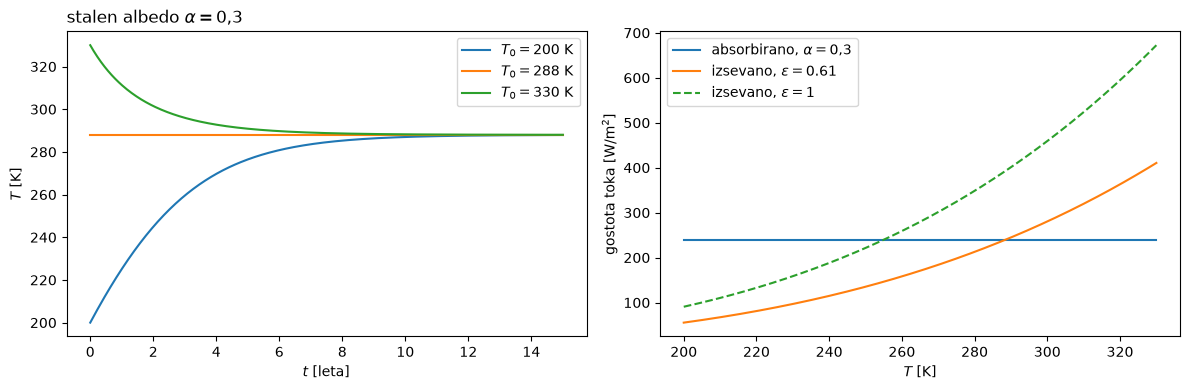

In [4]:
fig = plt.figure(figsize=(12, 4))
ax = fig.add_subplot(121)
konst = lambda T: 0.3 + 0 * T                      # stalen albedo
for eps in (1.0, eps0):
    Tr = T_ravn(0.3, eps)
    tau = C / (4 * eps * sigma * Tr**3) / leto
    print(f"eps = {eps:.3f}: T = {Tr:.1f} K = {Tr - 273.15:.1f} °C, tau = {tau:.2f} let")
for T0 in (200, 288, 330):
    t, T = potek_0d(T0, 15 * leto, eps=eps0, alfa=konst)
    ax.plot(t, T, label=f"$T_0 = {T0}$ K")
eps2 = eps0 - 3.7 / (sigma * 288**4)               # 2xCO2: izsevanje pri 288 K manjše za 3,7 W/m^2
print(f"2xCO2: eps = {eps2:.4f}, T = {T_ravn(0.3, eps2):.2f} K, dT = {T_ravn(0.3, eps2) - T_ravn(0.3, eps0):.2f} K")
ax.set_xlabel("$t$ [leta]")
ax.set_ylabel("$T$ [K]")
ax.set_title(r"stalen albedo $\alpha = 0{,}3$", loc="left")
ax.legend()
ax = fig.add_subplot(122)
Ts = np.linspace(200, 330, 300)
ax.plot(Ts, Q0 * (1 - 0.3) + 0 * Ts, label=r"absorbirano, $\alpha = 0{,}3$")
ax.plot(Ts, eps0 * sigma * Ts**4, label=rf"izsevano, $\varepsilon = {eps0:.2f}$")
ax.plot(Ts, sigma * Ts**4, "--", label=r"izsevano, $\varepsilon = 1$")
ax.set_xlabel("$T$ [K]")
ax.set_ylabel("gostota toka [W/m$^2$]")
ax.legend()
fig.tight_layout()
plt.show()

# Naloga 2 - Slika 2

mu = 0.9: 240.8 K (stabilno), 274.9 K (nestabilno), 280.5 K (stabilno)
mu = 1.0: 247.2 K (stabilno), 254.2 K (nestabilno), 288.0 K (stabilno)
mu = 1.1: 294.9 K (stabilno)


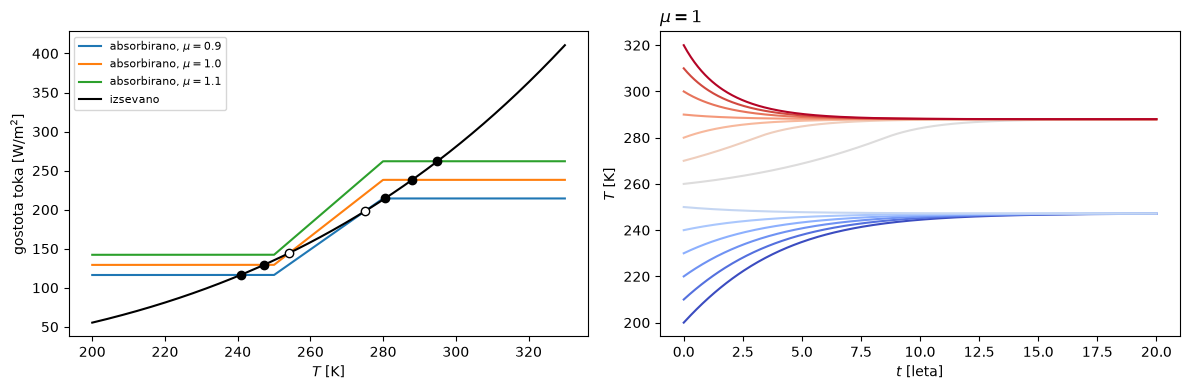

In [5]:
fig = plt.figure(figsize=(12, 4))
ax = fig.add_subplot(121)
Ts = np.linspace(200, 330, 500)
for mu in (0.9, 1.0, 1.1):
    ax.plot(Ts, mu * Q0 * (1 - alfa_led(Ts)), label=rf"absorbirano, $\mu = {mu}$")
ax.plot(Ts, eps0 * sigma * Ts**4, "k", label="izsevano")
for mu in (0.9, 1.0, 1.1):
    rav = ravnovesja_0d(mu, eps0)
    print(f"mu = {mu}: " + ", ".join(f"{Tr:.1f} K ({'stabilno' if st else 'nestabilno'})" for Tr, st in rav))
    for Tr, st in rav:
        ax.plot(Tr, eps0 * sigma * Tr**4, "o", mfc="k" if st else "w", mec="k")
ax.set_xlabel("$T$ [K]")
ax.set_ylabel("gostota toka [W/m$^2$]")
ax.legend(fontsize=8)
ax = fig.add_subplot(122)
for T0 in np.arange(200, 321, 10):
    t, T = potek_0d(float(T0), 20 * leto, mu=1.0, eps=eps0)
    ax.plot(t, T, color=plt.cm.coolwarm((T0 - 200) / 120))
ax.set_xlabel("$t$ [leta]")
ax.set_ylabel("$T$ [K]")
ax.set_title(r"$\mu = 1$", loc="left")
fig.tight_layout()
plt.show()

# Naloga 3 - Slika 3

$D$      : <T> =  14.33 °C, T_ekv =  29.1 °C, T_pol =  -13.5 °C, ledena meja =  71.8°
$D = 0$  : <T> =   9.20 °C, T_ekv =  57.6 °C, T_pol =  -64.3 °C, ledena meja =  45.8°


$5D$     : <T> =  14.81 °C, T_ekv =  18.8 °C, T_pol =    7.4 °C, ledena meja =  90.0°


2xCO$_2$ : <T> =  16.56 °C, T_ekv =  31.0 °C, T_pol =   -9.8 °C, ledena meja =  90.0°
2xCO2: d<T> = 2.23 K (brez ledu bi bilo 3,7/B = 1.77 K)


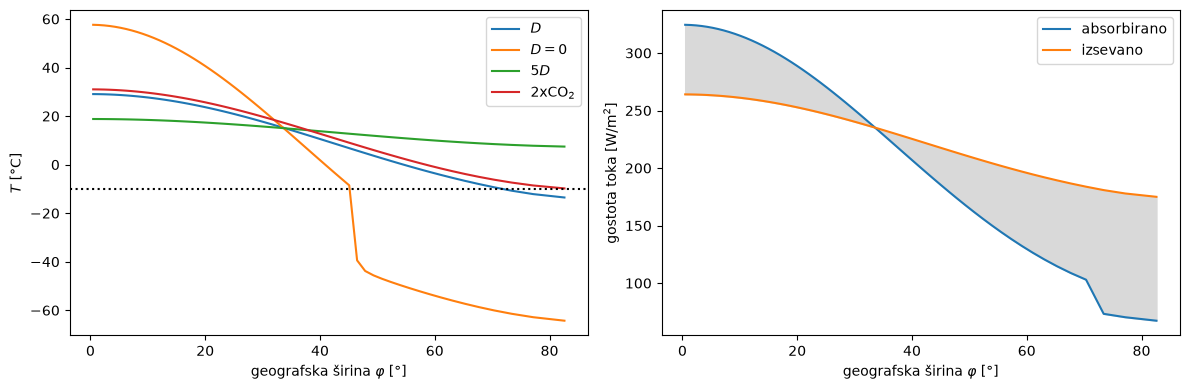

In [6]:
T_zac = np.full(N, 15.0)
fi = np.degrees(np.arcsin(x))
primeri = {}
for ime, kw in (("$D$", {}), ("$D = 0$", {"D": 0.0}), ("$5D$", {"D": 5 * D}), ("2xCO$_2$", {"A": A - 3.7})):
    T = ravnovesje_1d(T_zac, **kw)
    primeri[ime] = T
    print(f"{ime:9s}: <T> = {T.mean():6.2f} °C, T_ekv = {T[0]:5.1f} °C, T_pol = {T[-1]:6.1f} °C, "
          f"ledena meja = {ledena_meja(T):5.1f}°")
print(f"2xCO2: d<T> = {primeri['2xCO$_2$'].mean() - primeri['$D$'].mean():.2f} K (brez ledu bi bilo 3,7/B = {3.7 / B:.2f} K)")
fig = plt.figure(figsize=(12, 4))
ax = fig.add_subplot(121)
for ime, T in primeri.items():
    ax.plot(fi, T, label=ime)
ax.axhline(T_led, color="k", ls=":")
ax.set_xlabel(r"geografska širina $\varphi$ [°]")
ax.set_ylabel("$T$ [°C]")
ax.legend()
ax = fig.add_subplot(122)
T = primeri["$D$"]
s = 1 + s2 * P2
ax.plot(fi, Q1 * s * koalbedo(T), label="absorbirano")
ax.plot(fi, A + B * T, label="izsevano")
ax.fill_between(fi, Q1 * s * koalbedo(T), A + B * T, color="0.85")
ax.set_xlabel(r"geografska širina $\varphi$ [°]")
ax.set_ylabel("gostota toka [W/m$^2$]")
ax.legend()
fig.tight_layout()
plt.show()

# Naloga 4 - Slika 4

zmanjševanje: led se pojavi pri mu = 1.00 (ledena meja 71.8°), popolna poledenitev pri mu = 0.84 (zadnja ledena meja 21.5°)
povečevanje: odtalitev pri mu = 1.34
mu = 1.2: <T> = 37.2 °C (meja 90.0°) / -24.3 °C (meja 0.0°)
mu = 1.0: <T> = 14.4 °C (meja 71.8°) / -36.5 °C (meja 0.0°)
mu = 0.9: <T> = -1.5 °C (meja 45.8°) / -42.6 °C (meja 0.0°)


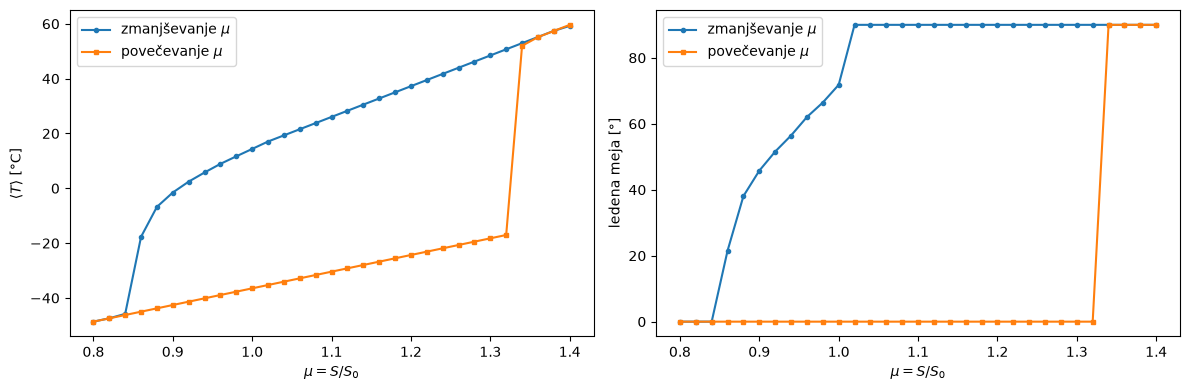

In [7]:
mus = np.round(np.arange(1.40, 0.80 - 1e-9, -0.02), 2)
T = primeri["$D$"].copy()
dol, gor = [], []
for mu in mus:
    T = ravnovesje_1d(T, mu)
    dol.append((T.mean(), ledena_meja(T)))
for mu in mus[::-1]:
    T = ravnovesje_1d(T, mu)
    gor.append((T.mean(), ledena_meja(T)))
dol, gor = np.array(dol), np.array(gor)[::-1]
meja = dol[:, 1]
print(f"zmanjševanje: led se pojavi pri mu = {mus[meja < 90].max():.2f} (ledena meja {meja[meja < 90][0]:.1f}°), "
      f"popolna poledenitev pri mu = {mus[meja == 0].max():.2f} (zadnja ledena meja {meja[meja > 0][-1]:.1f}°)")
print(f"povečevanje: odtalitev pri mu = {mus[gor[:, 1] > 0].min():.2f}")
for mu in (1.2, 1.0, 0.9):
    k = np.argmin(np.abs(mus - mu))
    print(f"mu = {mu}: <T> = {dol[k, 0]:.1f} °C (meja {dol[k, 1]:.1f}°) / {gor[k, 0]:.1f} °C (meja {gor[k, 1]:.1f}°)")
fig = plt.figure(figsize=(12, 4))
ax = fig.add_subplot(121)
ax.plot(mus, dol[:, 0], "o-", ms=3, label="zmanjševanje $\\mu$")
ax.plot(mus, gor[:, 0], "s-", ms=3, label="povečevanje $\\mu$")
ax.set_xlabel(r"$\mu = S/S_0$")
ax.set_ylabel(r"$\langle T\rangle$ [°C]")
ax.legend()
ax = fig.add_subplot(122)
ax.plot(mus, dol[:, 1], "o-", ms=3, label="zmanjševanje $\\mu$")
ax.plot(mus, gor[:, 1], "s-", ms=3, label="povečevanje $\\mu$")
ax.set_xlabel(r"$\mu = S/S_0$")
ax.set_ylabel("ledena meja [°]")
ax.legend()
fig.tight_layout()
plt.show()